In [63]:
import pandas as pd
import numpy as np
import sqlite3

df = pd.read_excel(
    "online_retail.xlsx",
    sheet_name="Year 2009-2010"
)
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (525461, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [64]:
df = df.drop_duplicates()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df = df.dropna(subset=["Customer ID"])
df["Invoice"] = df["Invoice"].astype(str)
df = df[~df["Invoice"].str.startswith("C")]
df = df[df["Quantity"] > 0]
df = df[df["Price"] > 0]
df["Description"] = df["Description"].fillna("Unknown")
df["Customer ID"] = df["Customer ID"].astype(int)
df["SalesAmount"] = df["Quantity"] * df["Price"]
print("Cleaned Dataset Shape:", df.shape)
df.head()

Cleaned Dataset Shape: (400916, 9)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SalesAmount
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


In [65]:
attribute_summary = pd.DataFrame({
    "Attribute": [
        "Invoice",
        "StockCode",
        "Description",
        "Quantity",
        "InvoiceDate",
        "Price",
        "Customer ID",
        "Country",
        "SalesAmount"
    ],
    "Type": [
        "String",
        "String",
        "String",
        "Integer",
        "DateTime",
        "Decimal",
        "Integer",
        "String",
        "Decimal"
    ],
    "Description": [
        "Invoice/transaction identifier",
        "Unique product code",
        "Product description",
        "Number of units purchased",
        "Date and time of transaction",
        "Unit price",
        "Customer identifier",
        "Customer country",
        "Quantity × Price"
    ],
    "Role in DW": [
        "Key",
        "Key",
        "Dimension",
        "Measure",
        "Dimension",
        "Measure",
        "Dimension/Key",
        "Dimension",
        "Measure"
    ]
})
attribute_summary

,Attribute,Type,Description,Role in DW
0,Invoice,String,Invoice/transaction identifier,Key
1,StockCode,String,Unique product code,Key
2,Description,String,Product description,Dimension
3,Quantity,Integer,Number of units purchased,Measure
4,InvoiceDate,DateTime,Date and time of transaction,Dimension
5,Price,Decimal,Unit price,Measure
6,Customer ID,Integer,Customer identifier,Dimension/Key
7,Country,String,Customer country,Dimension
8,SalesAmount,Decimal,Quantity × Price,Measure


In [66]:
df["Date"] = df["InvoiceDate"].dt.date
df["Day"] = df["InvoiceDate"].dt.day
df["Month"] = df["InvoiceDate"].dt.month
df["Quarter"] = df["InvoiceDate"].dt.quarter
df["Year"] = df["InvoiceDate"].dt.year
dim_time = df[
    ["Date", "Day", "Month", "Quarter", "Year"]
].drop_duplicates().reset_index(drop=True)
dim_time.insert(
    0,
    "time_key",
    range(1, len(dim_time) + 1)
)
dim_time.head()

,time_key,Date,Day,Month,Quarter,Year
0,1,2009-12-01,1,12,4,2009
1,2,2009-12-02,2,12,4,2009
2,3,2009-12-03,3,12,4,2009
3,4,2009-12-04,4,12,4,2009
4,5,2009-12-05,5,12,4,2009


In [67]:
dim_customer = df[
    ["Customer ID", "Country"]
].drop_duplicates(
    subset=["Customer ID"]
).reset_index(drop=True)
dim_customer.insert(
    0,
    "customer_key",
    range(1, len(dim_customer) + 1)
)
dim_customer.head()

,customer_key,Customer ID,Country
0,1,13085,United Kingdom
1,2,13078,United Kingdom
2,3,15362,United Kingdom
3,4,18102,United Kingdom
4,5,12682,France


In [68]:
dim_product = df[
    ["StockCode", "Description"]
].drop_duplicates(
    subset=["StockCode"]
).reset_index(drop=True)
dim_product.insert(
    0,
    "product_key",
    range(1, len(dim_product) + 1)
)
dim_product.head()

,product_key,StockCode,Description
0,1,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS
1,2,79323P,PINK CHERRY LIGHTS
2,3,79323W,WHITE CHERRY LIGHTS
3,4,22041,"RECORD FRAME 7"" SINGLE SIZE"
4,5,21232,STRAWBERRY CERAMIC TRINKET BOX


In [69]:
dim_location = df[
    ["Country"]
].drop_duplicates().reset_index(drop=True)
dim_location.insert(
    0,
    "location_key",
    range(1, len(dim_location) + 1)
)
dim_location.head()

,location_key,Country
0,1,United Kingdom
1,2,France
2,3,USA
3,4,Belgium
4,5,Australia


In [70]:
fact_sales = df.copy()
fact_sales = fact_sales.merge(
    dim_time[["time_key", "Date"]],
    on="Date",
    how="left"
)
fact_sales = fact_sales.merge(
    dim_customer[["customer_key", "Customer ID"]],
    on="Customer ID",
    how="left"
)
fact_sales = fact_sales.merge(
    dim_product[["product_key", "StockCode"]],
    on="StockCode",
    how="left"
)
fact_sales = fact_sales.merge(
    dim_location[["location_key", "Country"]],
    on="Country",
    how="left"
)
fact_sales.insert(
    0,
    "sales_key",
    range(1, len(fact_sales) + 1)
)
fact_sales = fact_sales[
    [
        "sales_key",
        "time_key",
        "product_key",
        "customer_key",
        "location_key",
        "SalesAmount",
        "Quantity"
    ]
]
fact_sales.head()

,sales_key,time_key,product_key,customer_key,location_key,SalesAmount,Quantity
0,1,1,1,1,1,83.4,12
1,2,1,2,1,1,81.0,12
2,3,1,3,1,1,81.0,12
3,4,1,4,1,1,100.8,48
4,5,1,5,1,1,30.0,24


In [71]:
conn = sqlite3.connect("ShopSmart_DataWarehouse.db")
dim_time.to_sql(
    "dim_time",
    conn,
    if_exists="replace",
    index=False
)
dim_product.to_sql(
    "dim_product",
    conn,
    if_exists="replace",
    index=False
)
dim_customer.to_sql(
    "dim_customer",
    conn,
    if_exists="replace",
    index=False
)
dim_location.to_sql(
    "dim_location",
    conn,
    if_exists="replace",
    index=False
)
# Load fact table
fact_sales.to_sql(
    "fact_sales",
    conn,
    if_exists="replace",
    index=False
)
print("Data Warehouse Created Successfully")

Data Warehouse Created Successfully


In [72]:
tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type='table';
    """,
    conn
)
tables

,name
0,dim_time
1,dim_product
2,dim_customer
3,dim_location
4,fact_sales


In [73]:
rollup = pd.read_sql_query(
    """
    SELECT
        l.Country,
        SUM(f.SalesAmount) AS total_sales
    FROM fact_sales f
    JOIN dim_location l
        ON f.location_key = l.location_key
    GROUP BY l.Country
    ORDER BY total_sales DESC;
    """,
    conn
)
rollup

,Country,total_sales
0,United Kingdom,7381644.433
1,EIRE,356041.860
2,Netherlands,268784.350
3,Germany,202025.391
4,France,146107.070
5,Sweden,53147.990
6,Denmark,50906.850
7,Spain,47568.650
8,Switzerland,43921.390
9,Australia,31446.800


In [74]:
drilldown = pd.read_sql_query(
    """
    SELECT
        t.Year,
        t.Quarter,
        SUM(f.SalesAmount) AS total_sales
    FROM fact_sales f
    JOIN dim_time t
        ON f.time_key = t.time_key
    GROUP BY
        t.Year,
        t.Quarter
    ORDER BY
        t.Year,
        t.Quarter;
    """,
    conn
)
drilldown

,Year,Quarter,total_sales
0,2009,4,683504.010
1,2010,1,1757340.099
2,2010,2,1826186.512
3,2010,3,2020974.721
4,2010,4,2510228.402


In [75]:
slice_2009 = pd.read_sql_query(
    """
    SELECT
        p.Description,
        SUM(f.SalesAmount) AS total_sales
    FROM fact_sales f
    JOIN dim_time t
        ON f.time_key = t.time_key
    JOIN dim_product p
        ON f.product_key = p.product_key
    WHERE t.Year = 2009
    GROUP BY p.Description
    ORDER BY total_sales DESC;
    """,
    conn
)
slice_2009.head(20)

,Description,total_sales
0,WHITE HANGING HEART T-LIGHT HOLDER,16425.51
1,EDWARDIAN PARASOL BLACK,8632.75
2,PAPER CHAIN KIT 50'S CHRISTMAS,7561.20
3,ASSORTED COLOUR BIRD ORNAMENT,7271.89
4,JUMBO BAG RED WHITE SPOTTY,6512.70
5,SCOTTIE DOG HOT WATER BOTTLE,6498.75
6,EDWARDIAN PARASOL RED,6108.25
7,WHITE CHERRY LIGHTS,6069.90
8,RED/WHITE DOTS RUFFLED UMBRELLA,5953.95
9,EDWARDIAN PARASOL NATURAL,5953.95


In [76]:
dice = pd.read_sql_query(
    """
    SELECT
        l.Country,
        p.Description,
        SUM(f.SalesAmount) AS total_sales
    FROM fact_sales f
    JOIN dim_location l
        ON f.location_key = l.location_key
    JOIN dim_product p
        ON f.product_key = p.product_key
    WHERE l.Country IN
        ('United Kingdom', 'Germany', 'France')
    GROUP BY
        l.Country,
        p.Description
    ORDER BY total_sales DESC;
    """,
    conn
)
dice.head(20)

,Country,Description,total_sales
0,United Kingdom,WHITE HANGING HEART T-LIGHT HOLDER,137684.96
1,United Kingdom,REGENCY CAKESTAND 3 TIER,123029.85
2,United Kingdom,JUMBO BAG RED WHITE SPOTTY,76601.10
3,United Kingdom,ASSORTED COLOUR BIRD ORNAMENT,65567.85
4,United Kingdom,Manual,53436.11
5,United Kingdom,DOOR MAT UNION FLAG,39356.30
6,United Kingdom,ROTATING SILVER ANGELS T-LIGHT HLDR,38510.55
7,United Kingdom,PAPER CHAIN KIT 50'S CHRISTMAS,35994.95
8,United Kingdom,RETRO SPOT CAKE STAND,33975.79
9,United Kingdom,VINTAGE UNION JACK BUNTING,33181.46


In [77]:
pivot = pd.read_sql_query(
    """
    SELECT
        p.Description,
        SUM(
            CASE
                WHEN l.Country = 'United Kingdom'
                THEN f.SalesAmount
                ELSE 0
            END
        ) AS United_Kingdom,
        SUM(
            CASE
                WHEN l.Country = 'Germany'
                THEN f.SalesAmount
                ELSE 0
            END
        ) AS Germany,
        SUM(
            CASE
                WHEN l.Country = 'France'
                THEN f.SalesAmount
                ELSE 0
            END
        ) AS France
    FROM fact_sales f
    JOIN dim_location l
        ON f.location_key = l.location_key
    JOIN dim_product p
        ON f.product_key = p.product_key
    GROUP BY p.Description
    ORDER BY
        United_Kingdom DESC;
    """,
    conn
)
pivot.head(20)

,Description,United_Kingdom,Germany,France
0,WHITE HANGING HEART T-LIGHT HOLDER,137684.96,123.90,118.00
1,REGENCY CAKESTAND 3 TIER,123029.85,4537.95,701.25
2,JUMBO BAG RED WHITE SPOTTY,76601.10,1033.50,1269.60
3,ASSORTED COLOUR BIRD ORNAMENT,65567.85,162.24,1453.12
4,Manual,53436.11,775.02,5020.70
5,DOOR MAT UNION FLAG,39356.30,93.46,555.36
6,ROTATING SILVER ANGELS T-LIGHT HLDR,38510.55,153.00,0.00
7,PAPER CHAIN KIT 50'S CHRISTMAS,35994.95,35.40,20.65
8,RETRO SPOT CAKE STAND,33975.79,1057.95,427.05
9,VINTAGE UNION JACK BUNTING,33181.46,229.50,102.00


In [78]:
conn.close()
print("Data Warehouse connection closed.")

Data Warehouse connection closed.


In [79]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

In [80]:
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

print("Reference Date:", reference_date)

Reference Date: 2010-12-10 20:01:00


In [81]:
rfm = df.groupby("Customer ID").agg(
    Recency=(
        "InvoiceDate",
        lambda x: (reference_date - x.max()).days
    ),
    Frequency=(
        "Invoice",
        "nunique"
    ),
    Monetary=(
        "SalesAmount",
        "sum"
    )
)
print("RFM table shape:", rfm.shape)
display(rfm.head())

RFM table shape: (4312, 3)


,Recency,Frequency,Monetary
Customer ID,,,
12346,165,11,372.86
12347,3,2,1323.32
12348,74,1,222.16
12349,43,3,2671.14
12351,11,1,300.93


In [82]:
median_monetary = rfm["Monetary"].median()
rfm["CustomerCategory"] = (
    rfm["Monetary"] > median_monetary
).astype(int)
print("Median Customer Spending:", median_monetary)
print("\nCustomer Category Distribution:")
print(
    rfm["CustomerCategory"]
    .value_counts()
    .rename(index={
        0: "Low Value",
        1: "High Value"
    })
)

Median Customer Spending: 701.615

Customer Category Distribution:
CustomerCategory
Low Value     2156
High Value    2156
Name: count, dtype: int64


In [83]:
X_class = rfm[["Recency", "Frequency"]]
y_class = rfm["CustomerCategory"].astype(int)
print("Features:")
display(X_class.head())
print("\nTarget:")
display(y_class.head())

Features:


,Recency,Frequency
Customer ID,,
12346,165,11
12347,3,2
12348,74,1
12349,43,3
12351,11,1



Target:


Customer ID
12346    0
12347    1
12348    0
12349    1
12351    0
Name: CustomerCategory, dtype: int64

In [84]:
X_train_class, X_test_class, y_train_class, y_test_class = (
    train_test_split(
        X_class,
        y_class,
        test_size=0.2,
        random_state=42,
        stratify=y_class
    )
)
print("Training samples:", len(X_train_class))
print("Testing samples:", len(X_test_class))

Training samples: 3449
Testing samples: 863


In [85]:
dt_model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)
print("Decision Tree model created successfully!")

Decision Tree model created successfully!


In [86]:
dt_model.fit(X_train_class, y_train_class)
print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [87]:
dt_pred = dt_model.predict(X_test_class)
print("Customer category predictions completed!")
print("\nFirst 10 predictions:")
print(dt_pred[:10])

Customer category predictions completed!

First 10 predictions:
[0 1 1 1 0 1 0 1 1 1]


In [88]:
dt_accuracy = accuracy_score(
    y_test_class,
    dt_pred
)
print(
    "Decision Tree Accuracy:",
    round(dt_accuracy * 100, 2),
    "%"
)

Decision Tree Accuracy: 82.97 %


In [89]:
print("\nClassification Report:")
print(
    classification_report(
        y_test_class,
        dt_pred,
        target_names=["Low Value", "High Value"],
        zero_division=0
    )
)


Classification Report:
              precision    recall  f1-score   support

   Low Value       0.83      0.83      0.83       432
  High Value       0.83      0.83      0.83       431

    accuracy                           0.83       863
   macro avg       0.83      0.83      0.83       863
weighted avg       0.83      0.83      0.83       863



In [90]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [91]:
required_columns = [
    "Customer ID", "Invoice", "InvoiceDate", "SalesAmount"
]
missing_columns = [
    col for col in required_columns if col not in df.columns
]
if missing_columns:
    raise ValueError(
        f"Missing columns in cleaned data: {missing_columns}. "
        "Run the Assessment 1 cleaning cells first."
    )
print("Cleaned dataset shape:", df.shape)
print("Unique customers:", df["Customer ID"].nunique())

Cleaned dataset shape: (400916, 14)
Unique customers: 4312


In [92]:
latest_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = df.groupby("Customer ID").agg(
    LatestDate=("InvoiceDate", "max"),
    Frequency=("Invoice", "nunique"),
    Monetary=("SalesAmount", "sum")
).reset_index()
rfm["Recency"] = (
    latest_date - rfm["LatestDate"]
).dt.days
rfm = rfm[
    ["Customer ID", "Recency", "Frequency", "Monetary"]
].copy()
print("\nRFM values:")
display(rfm.head(10))


RFM values:


,Customer ID,Recency,Frequency,Monetary
0,12346,165,11,372.86
1,12347,3,2,1323.32
2,12348,74,1,222.16
3,12349,43,3,2671.14
4,12351,11,1,300.93
5,12352,11,2,343.80
6,12353,44,1,317.76
7,12355,203,1,488.21
8,12356,16,3,3560.30
9,12357,24,2,12079.99


In [93]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)
rfm["RFM_Total"] = (
    rfm["R_Score"]
    + rfm["F_Score"]
    + rfm["M_Score"]
)
print("\nRFM scores:")
display(rfm.head(10))


RFM scores:


,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total
0,12346,165,11,372.86,2,5,2,252,9
1,12347,3,2,1323.32,5,2,4,524,11
2,12348,74,1,222.16,2,1,1,211,4
3,12349,43,3,2671.14,3,3,5,335,11
4,12351,11,1,300.93,5,1,2,512,8
5,12352,11,2,343.80,5,2,2,522,9
6,12353,44,1,317.76,3,1,2,312,6
7,12355,203,1,488.21,1,1,2,112,4
8,12356,16,3,3560.30,4,3,5,435,12
9,12357,24,2,12079.99,4,2,5,425,11


In [94]:
rfm_features = rfm[
    ["Recency", "Frequency", "Monetary"]
].copy()
rfm_log = np.log1p(rfm_features)
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)
print("\nScaled feature matrix shape:", rfm_scaled.shape)


Scaled feature matrix shape: (4312, 3)


In [95]:
silhouette_scores = {}

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(rfm_scaled)
    score = silhouette_score(rfm_scaled, labels)
    silhouette_scores[k] = score
score_table = pd.DataFrame({
    "Number of Clusters": list(silhouette_scores.keys()),
    "Silhouette Score": list(silhouette_scores.values())
})
print("\nSilhouette scores:")
display(score_table)
best_k = max(silhouette_scores, key=silhouette_scores.get)
print("Best k among tested values:", best_k)


Silhouette scores:


,Number of Clusters,Silhouette Score
0,2,0.422250
1,3,0.328367
2,4,0.331376
3,5,0.319187
4,6,0.311874


Best k among tested values: 2


In [96]:
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)
print("\nCustomer cluster assignments:")
display(rfm.head(10))


Customer cluster assignments:


,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total,Cluster
0,12346,165,11,372.86,2,5,2,252,9,0
1,12347,3,2,1323.32,5,2,4,524,11,1
2,12348,74,1,222.16,2,1,1,211,4,0
3,12349,43,3,2671.14,3,3,5,335,11,1
4,12351,11,1,300.93,5,1,2,512,8,0
5,12352,11,2,343.80,5,2,2,522,9,0
6,12353,44,1,317.76,3,1,2,312,6,0
7,12355,203,1,488.21,1,1,2,112,4,0
8,12356,16,3,3560.30,4,3,5,435,12,1
9,12357,24,2,12079.99,4,2,5,425,11,1


In [97]:
cluster_summary = rfm.groupby("Cluster").agg(
    Customers=("Customer ID", "count"),
    AverageRecency=("Recency", "mean"),
    AverageFrequency=("Frequency", "mean"),
    AverageMonetary=("Monetary", "mean"),
    MedianRecency=("Recency", "median"),
    MedianFrequency=("Frequency", "median"),
    MedianMonetary=("Monetary", "median")
).round(2)
print("\nCluster summary:")
display(cluster_summary)


Cluster summary:


,Customers,AverageRecency,AverageFrequency,AverageMonetary,MedianRecency,MedianFrequency,MedianMonetary
Cluster,,,,,,,
0,2670,128.99,1.73,517.66,91.0,1.0,369.42
1,1642,29.68,8.88,4516.50,17.0,6.0,2154.18


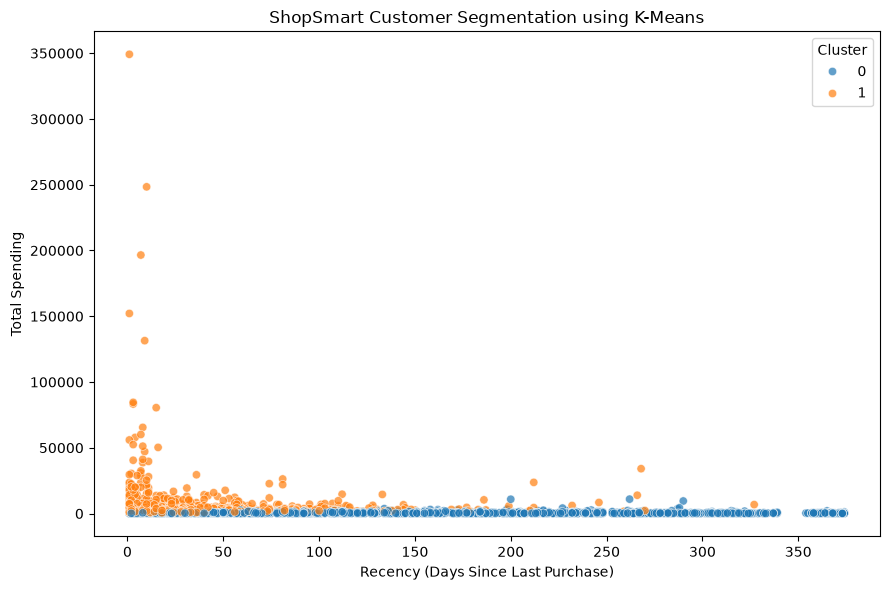

In [98]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Cluster",
    palette="tab10",
    alpha=0.7
)
plt.xlabel("Recency (Days Since Last Purchase)")
plt.ylabel("Total Spending")
plt.title("ShopSmart Customer Segmentation using K-Means")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

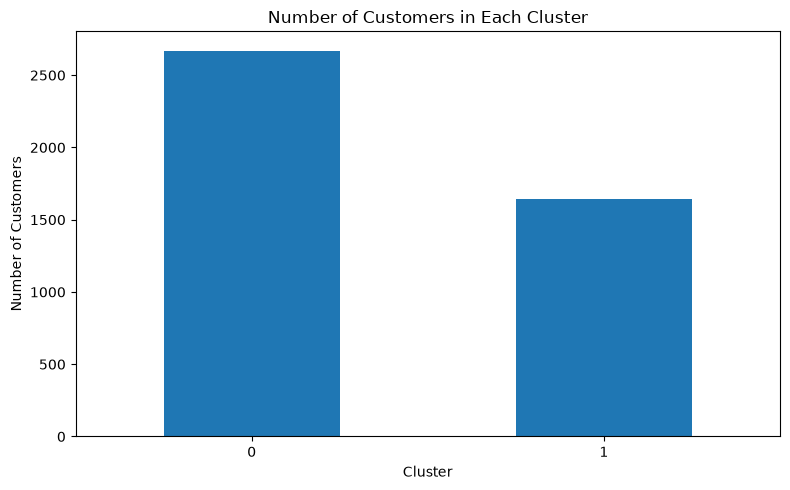

In [99]:
plt.figure(figsize=(8, 5))
cluster_summary["Customers"].plot(kind="bar")
plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [100]:
print("\nCONCLUSION")
print(
    "K-Means clustering grouped ShopSmart customers based on "
    "their Recency, Frequency and Monetary values."
)
print(
    "The cluster summary helps identify groups with different "
    "purchasing behaviours and supports customer loyalty analysis."
)


CONCLUSION
K-Means clustering grouped ShopSmart customers based on their Recency, Frequency and Monetary values.
The cluster summary helps identify groups with different purchasing behaviours and supports customer loyalty analysis.


In [101]:
rfm.to_csv(
    "ShopSmart_RFM_KMeans_2009_2010.csv",
    index=False
)
cluster_summary.to_csv(
    "ShopSmart_Cluster_Summary_2009_2010.csv"
)
print("\nResults saved successfully!")


Results saved successfully!


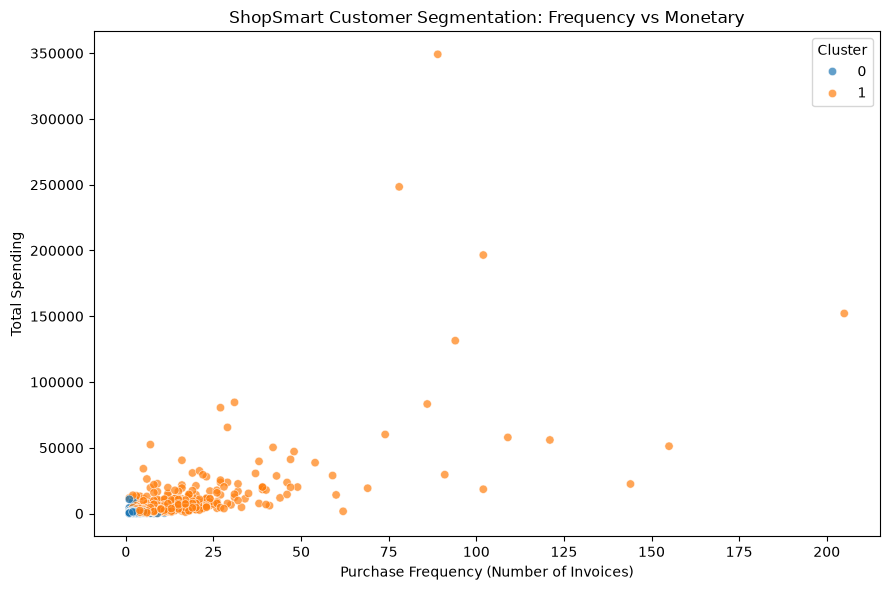

In [102]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="tab10",
    alpha=0.7
)
plt.title("ShopSmart Customer Segmentation: Frequency vs Monetary")
plt.xlabel("Purchase Frequency (Number of Invoices)")
plt.ylabel("Total Spending")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [106]:
from mlxtend.frequent_patterns import apriori, association_rules

In [107]:
basket_data = df[
    ["Invoice", "Description"]
].dropna().drop_duplicates()
print("Unique invoices:", basket_data["Invoice"].nunique())
print("Unique products:", basket_data["Description"].nunique())

Unique invoices: 19213
Unique products: 4444


In [108]:
basket = pd.crosstab(
    basket_data["Invoice"],
    basket_data["Description"]
).gt(0)
print("Basket matrix shape:", basket.shape)
display(basket.iloc[:5, :10])

Basket matrix shape: (19213, 4444)


Description,DOORMAT UNION JACK GUNS AND ROSES,3 STRIPEY MICE FELTCRAFT,4 PURPLE FLOCK DINNER CANDLES,ANIMAL STICKERS,BLACK PIRATE TREASURE CHEST,BROWN PIRATE TREASURE CHEST,Bank Charges,CAMPHOR WOOD PORTOBELLO MUSHROOM,CHERRY BLOSSOM DECORATIVE FLASK,FAIRY CAKE CANDLES
Invoice,,,,,,,,,,
489434,False,False,False,False,False,False,False,False,False,False
489435,False,False,False,False,False,False,False,False,False,False
489436,False,False,False,False,False,False,False,False,False,False
489437,False,False,False,False,False,False,False,False,False,False
489438,False,False,False,False,False,False,False,False,False,False


In [109]:
frequent_items = apriori(
    basket,
    min_support=0.02,
    use_colnames=True,
    low_memory=True
)
frequent_items = frequent_items.sort_values(
    by="support",
    ascending=False
)
print("Total frequent itemsets:", len(frequent_items))
print("\nTop 10 Frequent Itemsets:")
display(frequent_items.head(10))

Total frequent itemsets: 200

Top 10 Frequent Itemsets:


,support,itemsets
171,0.157237,frozenset({WHITE HANGING HEART T-LIGHT HOLDER})
141,0.087805,frozenset({REGENCY CAKESTAND 3 TIER})
159,0.069484,frozenset({STRAWBERRY CERAMIC TRINKET BOX})
6,0.069380,frozenset({ASSORTED COLOUR BIRD ORNAMENT})
58,0.061104,frozenset({HOME BUILDING BLOCK WORD})
103,0.060376,frozenset({PACK OF 72 RETRO SPOT CAKE CASES})
3,0.059127,frozenset({60 TEATIME FAIRY CAKE CASES})
68,0.055171,frozenset({JUMBO BAG RED RETROSPOT})
86,0.055067,frozenset({LUNCH BAG RED SPOTTY})
144,0.054182,frozenset({REX CASH+CARRY JUMBO SHOPPER})


In [110]:
if not frequent_items.empty:
    rules = association_rules(
        frequent_items,
        metric="confidence",
        min_threshold=0.30
    )
    if not rules.empty:
        rules = rules.sort_values(
            by="lift",
            ascending=False
        )
        print("Total association rules:", len(rules))
        print("\nTop 10 Association Rules:")
        display(
            rules[
                [
                    "antecedents",
                    "consequents",
                    "support",
                    "confidence",
                    "lift"
                ]
            ].head(10)
        )
    else:
        print("No association rules found.")
else:
    rules = pd.DataFrame()
    print("No frequent itemsets found.")

Total association rules: 25

Top 10 Association Rules:


,antecedents,consequents,support,confidence,lift
3,frozenset({WOODEN FRAME ANTIQUE WHITE }),frozenset({WOODEN PICTURE FRAME WHITE FINISH}),0.028835,0.549058,12.896162
4,frozenset({WOODEN PICTURE FRAME WHITE FINISH}),frozenset({WOODEN FRAME ANTIQUE WHITE }),0.028835,0.677262,12.896162
2,frozenset({STRAWBERRY CERAMIC TRINKET BOX}),frozenset({SWEETHEART CERAMIC TRINKET BOX}),0.032374,0.465918,11.078806
1,frozenset({SWEETHEART CERAMIC TRINKET BOX}),frozenset({STRAWBERRY CERAMIC TRINKET BOX}),0.032374,0.769802,11.078806
24,frozenset({HOT WATER BOTTLE TEA AND SYMPATHY}),frozenset({CHOCOLATE HOT WATER BOTTLE}),0.020091,0.458977,11.009155
23,frozenset({CHOCOLATE HOT WATER BOTTLE}),frozenset({HOT WATER BOTTLE TEA AND SYMPATHY}),0.020091,0.481898,11.009155
8,frozenset({HEART OF WICKER LARGE}),frozenset({HEART OF WICKER SMALL}),0.025556,0.492477,10.826051
7,frozenset({HEART OF WICKER SMALL}),frozenset({HEART OF WICKER LARGE}),0.025556,0.561785,10.826051
14,frozenset({LUNCH BAG SUKI DESIGN }),frozenset({LUNCH BAG SPACEBOY DESIGN }),0.023630,0.475891,10.058629
13,frozenset({LUNCH BAG SPACEBOY DESIGN }),frozenset({LUNCH BAG SUKI DESIGN }),0.023630,0.499450,10.058629


In [111]:
if not rules.empty:
    best_rule = rules.iloc[0]
    print("STRONGEST RULE BY LIFT")
    print("-" * 40)
    print("Antecedents:", best_rule["antecedents"])
    print("Consequents:", best_rule["consequents"])
    print("Support:", round(best_rule["support"], 4))
    print("Confidence:", round(best_rule["confidence"], 4))
    print("Lift:", round(best_rule["lift"], 4))
else:
    print("No association rules available.")

STRONGEST RULE BY LIFT
----------------------------------------
Antecedents: frozenset({'WOODEN FRAME ANTIQUE WHITE '})
Consequents: frozenset({'WOODEN PICTURE FRAME WHITE FINISH'})
Support: 0.0288
Confidence: 0.5491
Lift: 12.8962


In [112]:
if not rules.empty:
    best_rule = rules.iloc[0]
    antecedents = ", ".join(
        sorted(list(best_rule["antecedents"]))
    )
    consequents = ", ".join(
        sorted(list(best_rule["consequents"]))
    )
    print("SHOPSMART PRODUCT RECOMMENDATION")
    print("-" * 40)
    print("If a customer purchases:", antecedents)
    print("Recommend:", consequents)
    print("Confidence:", round(best_rule["confidence"] * 100, 2), "%")
    print("Lift:", round(best_rule["lift"], 2))
else:
    print("No recommendations available.")

SHOPSMART PRODUCT RECOMMENDATION
----------------------------------------
If a customer purchases: WOODEN FRAME ANTIQUE WHITE 
Recommend: WOODEN PICTURE FRAME WHITE FINISH
Confidence: 54.91 %
Lift: 12.9


In [118]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [119]:
df["SalesAmount"] = df["Quantity"] * df["Price"]
print("Sales Amount calculated successfully!")
display(df.head())

Sales Amount calculated successfully!


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SalesAmount,Date,Day,Month,Quarter,Year
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4,2009-12-01,1,12,4,2009
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0,2009-12-01,1,12,4,2009
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0,2009-12-01,1,12,4,2009
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8,2009-12-01,1,12,4,2009
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0,2009-12-01,1,12,4,2009


In [120]:
invoices = df.groupby(
    ["Customer ID", "Invoice", "InvoiceDate"],
    as_index=False
).agg(
    PurchaseValue=("SalesAmount", "sum")
)
print("Invoice purchase values calculated successfully!")
display(invoices.head())

Invoice purchase values calculated successfully!


,Customer ID,Invoice,InvoiceDate,PurchaseValue
0,12346,491725,2009-12-14 08:34:00,45.0
1,12346,491742,2009-12-14 11:00:00,22.5
2,12346,491744,2009-12-14 11:02:00,22.5
3,12346,492718,2009-12-18 10:47:00,22.5
4,12346,492722,2009-12-18 10:55:00,1.0


In [121]:
invoices = invoices.sort_values(
    ["Customer ID", "InvoiceDate", "Invoice"]
).reset_index(drop=True)
display(invoices.head())

,Customer ID,Invoice,InvoiceDate,PurchaseValue
0,12346,491725,2009-12-14 08:34:00,45.0
1,12346,491742,2009-12-14 11:00:00,22.5
2,12346,491744,2009-12-14 11:02:00,22.5
3,12346,492718,2009-12-18 10:47:00,22.5
4,12346,492722,2009-12-18 10:55:00,1.0


In [122]:
g = invoices.groupby("Customer ID")["PurchaseValue"]
for i in range(1, 4):
    invoices[f"PreviousPurchase_{i}"] = g.shift(i)
display(invoices.head(10))

,Customer ID,Invoice,InvoiceDate,PurchaseValue,PreviousPurchase_1,PreviousPurchase_2,PreviousPurchase_3
0,12346,491725,2009-12-14 08:34:00,45.00,NaN,NaN,NaN
1,12346,491742,2009-12-14 11:00:00,22.50,45.0,NaN,NaN
2,12346,491744,2009-12-14 11:02:00,22.50,22.5,45.0,NaN
3,12346,492718,2009-12-18 10:47:00,22.50,22.5,22.5,45.0
4,12346,492722,2009-12-18 10:55:00,1.00,22.5,22.5,22.5
5,12346,493410,2010-01-04 09:24:00,22.50,1.0,22.5,22.5
6,12346,493412,2010-01-04 09:53:00,22.50,22.5,1.0,22.5
7,12346,494450,2010-01-14 13:50:00,22.50,22.5,22.5,1.0
8,12346,495295,2010-01-22 13:30:00,22.50,22.5,22.5,22.5
9,12346,499763,2010-03-02 13:08:00,27.05,22.5,22.5,22.5


In [123]:
invoices["AveragePreviousPurchase"] = g.transform(
    lambda s: s.shift(1).expanding().mean()
)
display(invoices.head(10))

,Customer ID,Invoice,InvoiceDate,PurchaseValue,PreviousPurchase_1,PreviousPurchase_2,PreviousPurchase_3,AveragePreviousPurchase
0,12346,491725,2009-12-14 08:34:00,45.00,NaN,NaN,NaN,NaN
1,12346,491742,2009-12-14 11:00:00,22.50,45.0,NaN,NaN,45.000000
2,12346,491744,2009-12-14 11:02:00,22.50,22.5,45.0,NaN,33.750000
3,12346,492718,2009-12-18 10:47:00,22.50,22.5,22.5,45.0,30.000000
4,12346,492722,2009-12-18 10:55:00,1.00,22.5,22.5,22.5,28.125000
5,12346,493410,2010-01-04 09:24:00,22.50,1.0,22.5,22.5,22.700000
6,12346,493412,2010-01-04 09:53:00,22.50,22.5,1.0,22.5,22.666667
7,12346,494450,2010-01-14 13:50:00,22.50,22.5,22.5,1.0,22.642857
8,12346,495295,2010-01-22 13:30:00,22.50,22.5,22.5,22.5,22.625000
9,12346,499763,2010-03-02 13:08:00,27.05,22.5,22.5,22.5,22.611111


In [124]:
invoices["DaysSincePrevious"] = (
    invoices.groupby("Customer ID")["InvoiceDate"]
    .diff()
    .dt.total_seconds() / 86400
)
display(invoices.head(10))

,Customer ID,Invoice,InvoiceDate,PurchaseValue,PreviousPurchase_1,PreviousPurchase_2,PreviousPurchase_3,AveragePreviousPurchase,DaysSincePrevious
0,12346,491725,2009-12-14 08:34:00,45.00,NaN,NaN,NaN,NaN,NaN
1,12346,491742,2009-12-14 11:00:00,22.50,45.0,NaN,NaN,45.000000,0.101389
2,12346,491744,2009-12-14 11:02:00,22.50,22.5,45.0,NaN,33.750000,0.001389
3,12346,492718,2009-12-18 10:47:00,22.50,22.5,22.5,45.0,30.000000,3.989583
4,12346,492722,2009-12-18 10:55:00,1.00,22.5,22.5,22.5,28.125000,0.005556
5,12346,493410,2010-01-04 09:24:00,22.50,1.0,22.5,22.5,22.700000,16.936806
6,12346,493412,2010-01-04 09:53:00,22.50,22.5,1.0,22.5,22.666667,0.020139
7,12346,494450,2010-01-14 13:50:00,22.50,22.5,22.5,1.0,22.642857,10.164583
8,12346,495295,2010-01-22 13:30:00,22.50,22.5,22.5,22.5,22.625000,7.986111
9,12346,499763,2010-03-02 13:08:00,27.05,22.5,22.5,22.5,22.611111,38.984722


In [125]:
invoices["NextPurchaseValue"] = g.shift(-1)
display(
    invoices[
        [
            "Customer ID",
            "InvoiceDate",
            "PurchaseValue",
            "NextPurchaseValue"
        ]
    ].head(10)
)

,Customer ID,InvoiceDate,PurchaseValue,NextPurchaseValue
0,12346,2009-12-14 08:34:00,45.00,22.50
1,12346,2009-12-14 11:00:00,22.50,22.50
2,12346,2009-12-14 11:02:00,22.50,22.50
3,12346,2009-12-18 10:47:00,22.50,1.00
4,12346,2009-12-18 10:55:00,1.00,22.50
5,12346,2010-01-04 09:24:00,22.50,22.50
6,12346,2010-01-04 09:53:00,22.50,22.50
7,12346,2010-01-14 13:50:00,22.50,22.50
8,12346,2010-01-22 13:30:00,22.50,27.05
9,12346,2010-03-02 13:08:00,27.05,142.31


In [126]:
features = [
    "PreviousPurchase_1",
    "PreviousPurchase_2",
    "PreviousPurchase_3",
    "AveragePreviousPurchase",
    "DaysSincePrevious"
]
data = invoices.dropna(
    subset=features + ["NextPurchaseValue"]
).copy()
print("Original invoice records:", len(invoices))
print("Records available for prediction:", len(data))
display(data.head())

Original invoice records: 19248
Records available for prediction: 8391


,Customer ID,Invoice,InvoiceDate,PurchaseValue,PreviousPurchase_1,PreviousPurchase_2,PreviousPurchase_3,AveragePreviousPurchase,DaysSincePrevious,NextPurchaseValue
3,12346,492718,2009-12-18 10:47:00,22.5,22.5,22.5,45.0,30.000000,3.989583,1.0
4,12346,492722,2009-12-18 10:55:00,1.0,22.5,22.5,22.5,28.125000,0.005556,22.5
5,12346,493410,2010-01-04 09:24:00,22.5,1.0,22.5,22.5,22.700000,16.936806,22.5
6,12346,493412,2010-01-04 09:53:00,22.5,22.5,1.0,22.5,22.666667,0.020139,22.5
7,12346,494450,2010-01-14 13:50:00,22.5,22.5,22.5,1.0,22.642857,10.164583,22.5


In [127]:
data = data.sort_values("InvoiceDate").reset_index(drop=True)
split = int(len(data) * 0.8)
X_train = data[features].iloc[:split]
X_test = data[features].iloc[split:]
y_train = data["NextPurchaseValue"].iloc[:split]
y_test = data["NextPurchaseValue"].iloc[split:]
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 6712
Testing records: 1679


In [128]:
model = RandomForestRegressor(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)
print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [129]:
predictions = model.predict(X_test)
print("Predictions generated successfully!")

Predictions generated successfully!


In [130]:
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
r2 = r2_score(y_test, predictions)
print("Random Forest Regression Results")
print("--------------------------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("R2 Score:", round(r2, 4))

Random Forest Regression Results
--------------------------------
MAE: 379.03
MSE: 981182.39
R2 Score: 0.0785


In [131]:
comparison = pd.DataFrame({
    "Actual Next Purchase Value": y_test.values[:10],
    "Predicted Next Purchase Value": predictions[:10]
})
display(comparison.round(2))

,Actual Next Purchase Value,Predicted Next Purchase Value
0,316.95,318.42
1,125.70,355.88
2,285.00,378.43
3,207.71,335.15
4,96.45,246.65
5,96.45,201.44
6,393.95,334.67
7,167.85,324.28
8,249.54,195.78
9,175.50,529.35


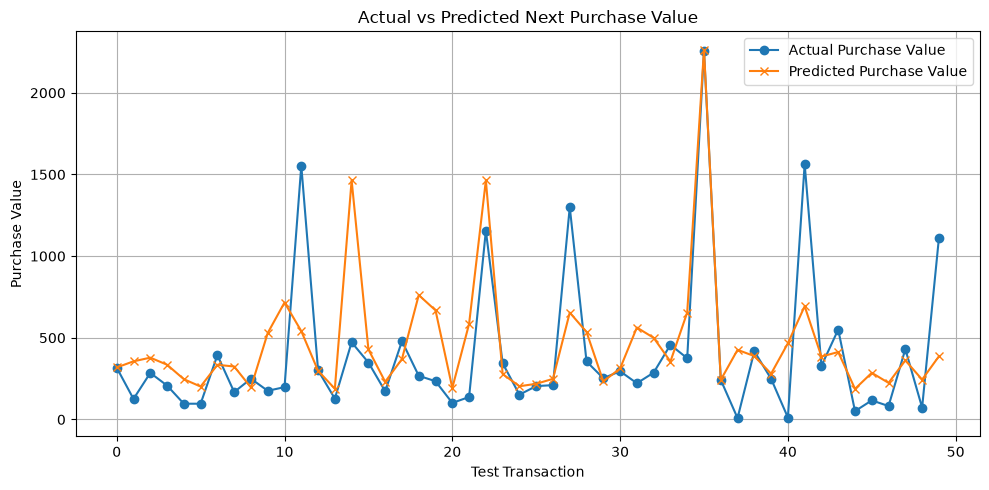

In [132]:
plt.figure(figsize=(10, 5))
plt.plot(
    y_test.values[:50],
    label="Actual Purchase Value",
    marker="o"
)
plt.plot(
    predictions[:50],
    label="Predicted Purchase Value",
    marker="x"
)
plt.title("Actual vs Predicted Next Purchase Value")
plt.xlabel("Test Transaction")
plt.ylabel("Purchase Value")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [133]:
import plotly.express as px
import plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import display, HTML
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.tree import plot_tree
sns.set_theme(style="darkgrid")
print("ShopSmart Dashboard libraries loaded successfully!")

ShopSmart Dashboard libraries loaded successfully!


In [134]:
required_variables = [
    "df",
    "rfm",
    "dt_model",
    "y_test_class",
    "dt_pred",
    "frequent_items",
    "rules",
    "y_test",
    "predictions"
]
missing_variables = [
    name for name in required_variables
    if name not in globals()
]
if missing_variables:
    print("Missing variables:", missing_variables)
    print("Run the corresponding algorithm cells first.")
else:
    print("All required algorithm outputs are available!")

All required algorithm outputs are available!


In [135]:
total_customers = len(rfm)
total_sales = df["SalesAmount"].sum()
total_invoices = df["Invoice"].nunique()
total_products = df["Description"].nunique()
dt_accuracy = accuracy_score(
    y_test_class,
    dt_pred
)

mae = mean_absolute_error(
    y_test,
    predictions
)
mse = mean_squared_error(
    y_test,
    predictions
)
rmse = np.sqrt(mse)
r2 = r2_score(
    y_test,
    predictions
)
print("Customers:", f"{total_customers:,}")
print("Sales:", f"{total_sales:,.2f}")
print("Invoices:", f"{total_invoices:,}")
print("Products:", f"{total_products:,}")
print("Decision Tree Accuracy:", f"{dt_accuracy * 100:.2f}%")
print("Prediction MAE:", f"{mae:.2f}")
print("Prediction RMSE:", f"{rmse:.2f}")
print("Prediction R²:", f"{r2:.4f}")

Customers: 4,312
Sales: 8,798,233.74
Invoices: 19,213
Products: 4,444
Decision Tree Accuracy: 82.97%
Prediction MAE: 379.03
Prediction RMSE: 990.55
Prediction R²: 0.0785


In [136]:
possible_cluster_columns = [
    "Cluster",
    "cluster",
    "KMeans_Cluster",
    "CustomerCluster",
    "KMeans_Cluster_Label"
]
cluster_column = next(
    (
        col for col in possible_cluster_columns
        if col in rfm.columns
    ),
    None
)
print("Available RFM columns:")
print(rfm.columns.tolist())
print("\nDetected cluster column:", cluster_column)

Available RFM columns:
['Recency', 'Frequency', 'Monetary', 'CustomerCategory']

Detected cluster column: None


In [138]:
from IPython.display import display, HTML
display(HTML("""
<div style="
    background: linear-gradient(135deg, #111827, #312e81, #164e63);
    color: white;
    padding: 30px;
    border-radius: 18px;
    text-align: center;
    margin-bottom: 20px;
">
    <h1 style="font-size: 38px; margin-bottom: 8px;">
        🛍️ ShopSmart
    </h1>
    <h3>
        Customer Loyalty & Churn Prediction Analytics
    </h3>
    <p style="font-size: 15px;">
        Customer Classification |
        K-Means Clustering |
        Association Rule Mining |
        Purchase Prediction
    </p>
    <p style="color: #cbd5e1;">
        Online Retail II Dataset — 2009–2010
    </p>
</div>
"""))

In [140]:
from IPython.display import display, HTML
display(HTML(f"""
<div style="
    display: flex;
    gap: 15px;
    flex-wrap: wrap;
    margin: 20px 0;
">
    <div style="
        flex: 1;
        min-width: 180px;
        background: #172033;
        color: white;
        padding: 22px;
        border-radius: 15px;
        text-align: center;
        box-shadow: 0 4px 10px rgba(0,0,0,0.2);
    ">
        <div style="color: #94a3b8; font-size: 14px;">
            👥 Total Customers
        </div>
        <div style="font-size: 28px; font-weight: bold; margin-top: 8px;">
            {total_customers:,}
        </div>
    </div>
    <div style="
        flex: 1;
        min-width: 180px;
        background: #172033;
        color: white;
        padding: 22px;
        border-radius: 15px;
        text-align: center;
        box-shadow: 0 4px 10px rgba(0,0,0,0.2);
    ">
        <div style="color: #94a3b8; font-size: 14px;">
            💰 Total Sales
        </div>
        <div style="font-size: 28px; font-weight: bold; margin-top: 8px;">
            {total_sales:,.2f}
        </div>
    </div>
    <div style="
        flex: 1;
        min-width: 180px;
        background: #172033;
        color: white;
        padding: 22px;
        border-radius: 15px;
        text-align: center;
        box-shadow: 0 4px 10px rgba(0,0,0,0.2);
    ">
        <div style="color: #94a3b8; font-size: 14px;">
            🧾 Total Invoices
        </div>
        <div style="font-size: 28px; font-weight: bold; margin-top: 8px;">
            {total_invoices:,}
        </div>
    </div>
    <div style="
        flex: 1;
        min-width: 180px;
        background: #172033;
        color: white;
        padding: 22px;
        border-radius: 15px;
        text-align: center;
        box-shadow: 0 4px 10px rgba(0,0,0,0.2);
    ">
        <div style="color: #94a3b8; font-size: 14px;">
            🛍️ Unique Products
        </div>
        <div style="font-size: 28px; font-weight: bold; margin-top: 8px;">
            {total_products:,}
        </div>
    </div>
</div>
"""))

🌳 DECISION TREE CLASSIFICATION

✅ Decision Tree Accuracy: 82.97%

📋 Classification Report
----------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.83      0.83      0.83       432
           1       0.83      0.83      0.83       431

    accuracy                           0.83       863
   macro avg       0.83      0.83      0.83       863
weighted avg       0.83      0.83      0.83       863



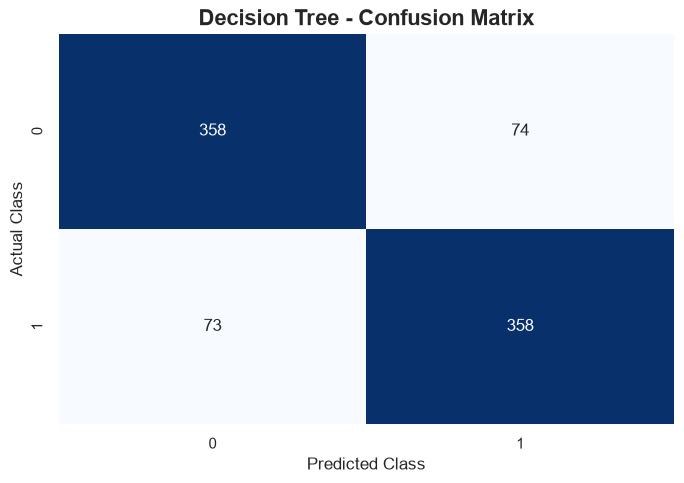


🌳 Decision Tree Visualization
----------------------------------------------------------------------


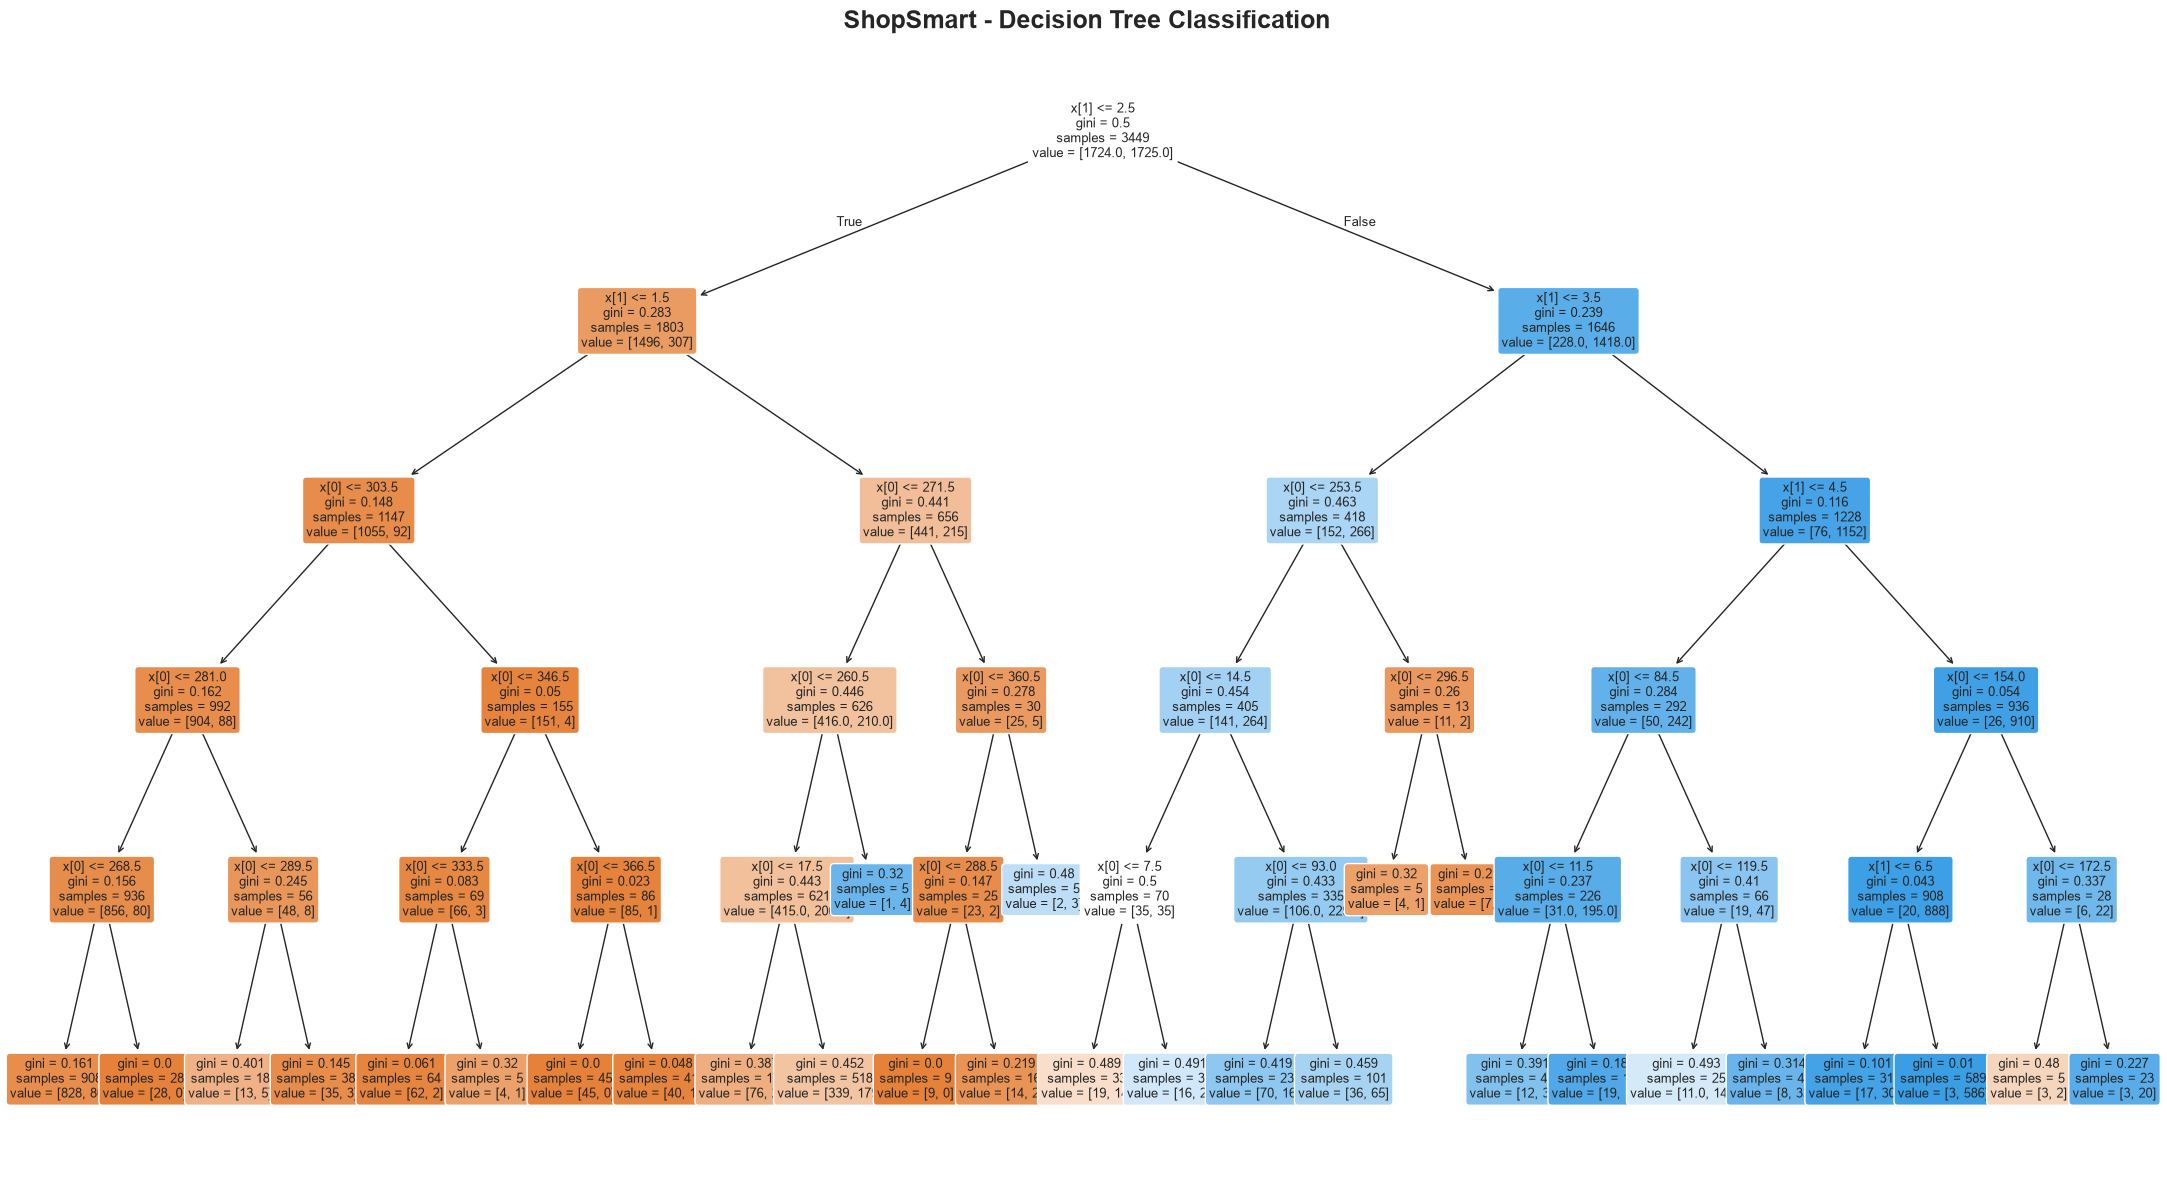

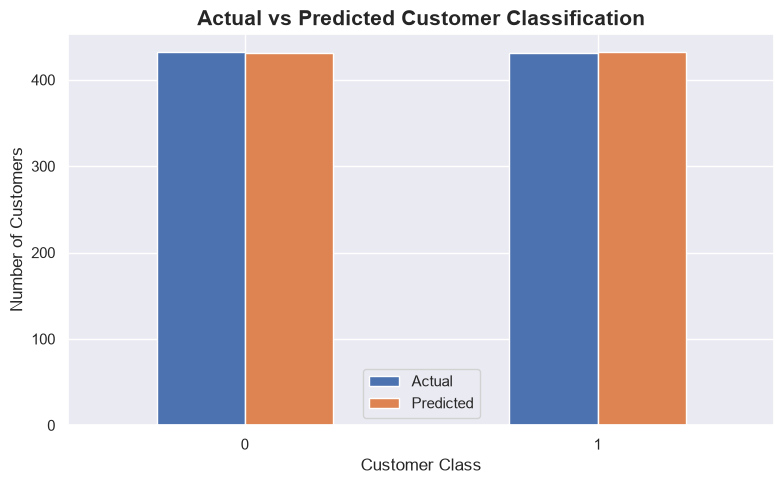


✅ CLASSIFICATION ANALYSIS COMPLETED


In [142]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 70)
print("🌳 DECISION TREE CLASSIFICATION")
print("=" * 70)
if "dt_model" not in globals():
    print("❌ dt_model is not defined.")
    print("Run your Decision Tree model cell first.")

elif "y_test_class" not in globals():
    print("❌ y_test_class is not defined.")
    print("Run your classification train/test cell first.")

elif "dt_pred" not in globals():
    print("❌ dt_pred is not defined.")
    print("Run your Decision Tree prediction cell first.")

else:
    accuracy = accuracy_score(
        y_test_class,
        dt_pred
    )
    print(f"\n✅ Decision Tree Accuracy: {accuracy * 100:.2f}%")
    print("\n📋 Classification Report")
    print("-" * 70)
    print(
        classification_report(
            y_test_class,
            dt_pred,
            zero_division=0
        )
    )
    cm = confusion_matrix(
        y_test_class,
        dt_pred
    )
    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False
    )
    plt.title(
        "Decision Tree - Confusion Matrix",
        fontsize=16,
        fontweight="bold"
    )
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()
    plt.show()
    print("\n🌳 Decision Tree Visualization")
    print("-" * 70)
    plt.figure(figsize=(22, 12))
    plot_tree(
        dt_model,
        filled=True,
        rounded=True,
        fontsize=9
    )
    plt.title(
        "ShopSmart - Decision Tree Classification",
        fontsize=18,
        fontweight="bold"
    )
    plt.tight_layout()
    plt.show()
    actual_counts = pd.Series(y_test_class).value_counts().sort_index()
    predicted_counts = pd.Series(dt_pred).value_counts().sort_index()
    comparison = pd.DataFrame({
        "Actual": actual_counts,
        "Predicted": predicted_counts
    }).fillna(0)
    comparison.plot(
        kind="bar",
        figsize=(8, 5)
    )
    plt.title(
        "Actual vs Predicted Customer Classification",
        fontsize=15,
        fontweight="bold"
    )
    plt.xlabel("Customer Class")
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
print("\n" + "=" * 70)
print("✅ CLASSIFICATION ANALYSIS COMPLETED")
print("=" * 70)

👥 CUSTOMER CLUSTERING

✅ Number of Clusters: 4
✅ Silhouette Score: 0.611

📊 Cluster Distribution
----------------------------------------------------------------------
Cluster
0    3204
1    1047
2       5
3      56
Name: count, dtype: int64


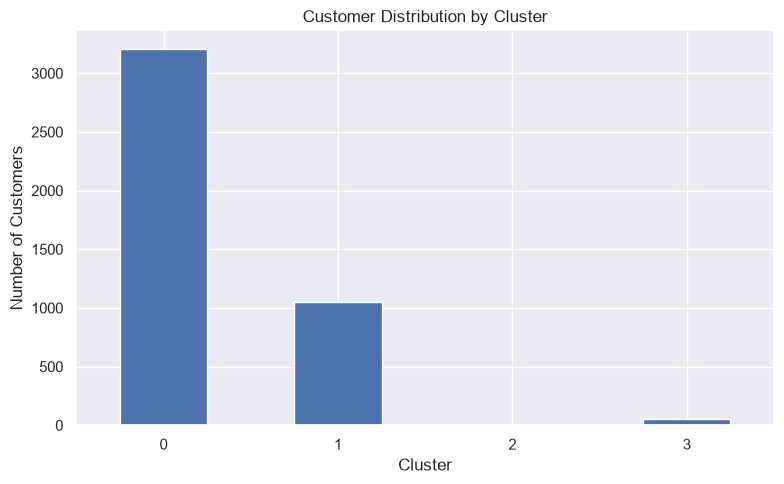

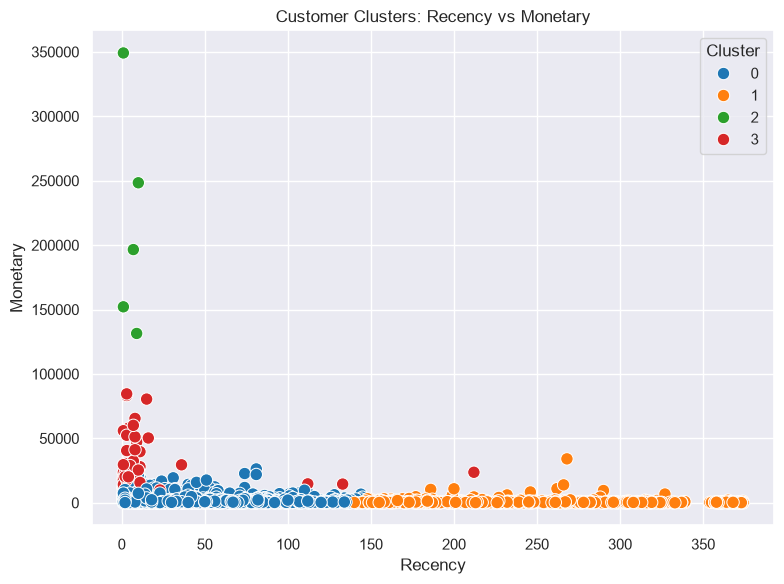


📋 Cluster Summary
----------------------------------------------------------------------
         Recency  Frequency   Monetary
Cluster                               
0          43.03       4.46    1710.65
1         242.98       1.66     593.54
2           5.60     113.60  215535.00
3          14.91      47.02   28896.42


<Figure size 900x500 with 0 Axes>

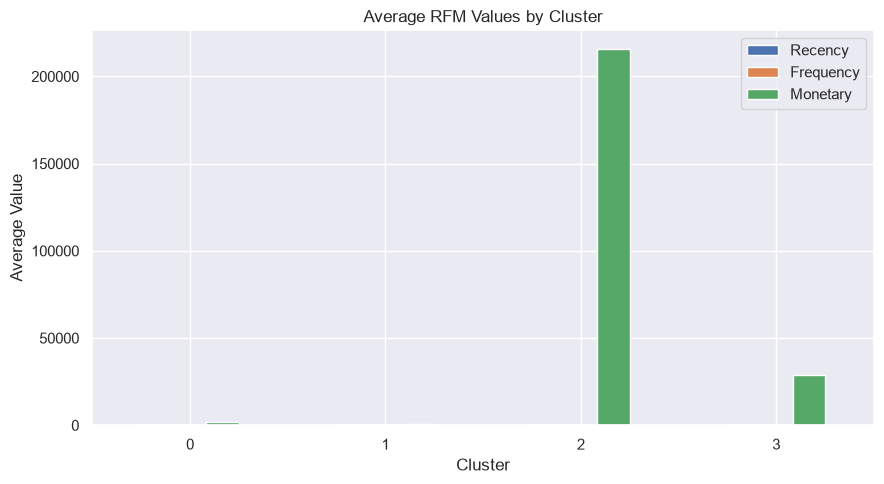


✅ CLUSTERING ANALYSIS COMPLETED


In [146]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 70)
print("👥 CUSTOMER CLUSTERING")
print("=" * 70)
features = ["Recency", "Frequency", "Monetary"]
X = rfm[features].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(X_scaled)
sil_score = silhouette_score(X_scaled, rfm["Cluster"])
print(f"\n✅ Number of Clusters: 4")
print(f"✅ Silhouette Score: {sil_score:.3f}")
print("\n📊 Cluster Distribution")
print("-" * 70)
cluster_counts = rfm["Cluster"].value_counts().sort_index()
print(cluster_counts)
plt.figure(figsize=(8, 5))
cluster_counts.plot(kind="bar")
plt.title("Customer Distribution by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Cluster",
    palette="tab10",
    s=80
)
plt.title("Customer Clusters: Recency vs Monetary")
plt.xlabel("Recency")
plt.ylabel("Monetary")
plt.tight_layout()
plt.show()
print("\n📋 Cluster Summary")
print("-" * 70)
cluster_summary = rfm.groupby("Cluster")[features].mean().round(2)
print(cluster_summary)
plt.figure(figsize=(9, 5))
cluster_summary.plot(kind="bar", figsize=(9, 5))
plt.title("Average RFM Values by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print("\n" + "=" * 70)
print("✅ CLUSTERING ANALYSIS COMPLETED")
print("=" * 70)

🛒 ASSOCIATION RULE MINING

✅ Total Rules Generated: 25

📋 Top Association Rules
----------------------------------------------------------------------


,antecedents,consequents,support,confidence,lift
3,frozenset({WOODEN FRAME ANTIQUE WHITE }),frozenset({WOODEN PICTURE FRAME WHITE FINISH}),0.028835,0.549058,12.896162
4,frozenset({WOODEN PICTURE FRAME WHITE FINISH}),frozenset({WOODEN FRAME ANTIQUE WHITE }),0.028835,0.677262,12.896162
2,frozenset({STRAWBERRY CERAMIC TRINKET BOX}),frozenset({SWEETHEART CERAMIC TRINKET BOX}),0.032374,0.465918,11.078806
1,frozenset({SWEETHEART CERAMIC TRINKET BOX}),frozenset({STRAWBERRY CERAMIC TRINKET BOX}),0.032374,0.769802,11.078806
24,frozenset({HOT WATER BOTTLE TEA AND SYMPATHY}),frozenset({CHOCOLATE HOT WATER BOTTLE}),0.020091,0.458977,11.009155
23,frozenset({CHOCOLATE HOT WATER BOTTLE}),frozenset({HOT WATER BOTTLE TEA AND SYMPATHY}),0.020091,0.481898,11.009155
8,frozenset({HEART OF WICKER LARGE}),frozenset({HEART OF WICKER SMALL}),0.025556,0.492477,10.826051
7,frozenset({HEART OF WICKER SMALL}),frozenset({HEART OF WICKER LARGE}),0.025556,0.561785,10.826051
14,frozenset({LUNCH BAG SUKI DESIGN }),frozenset({LUNCH BAG SPACEBOY DESIGN }),0.023630,0.475891,10.058629
13,frozenset({LUNCH BAG SPACEBOY DESIGN }),frozenset({LUNCH BAG SUKI DESIGN }),0.023630,0.499450,10.058629


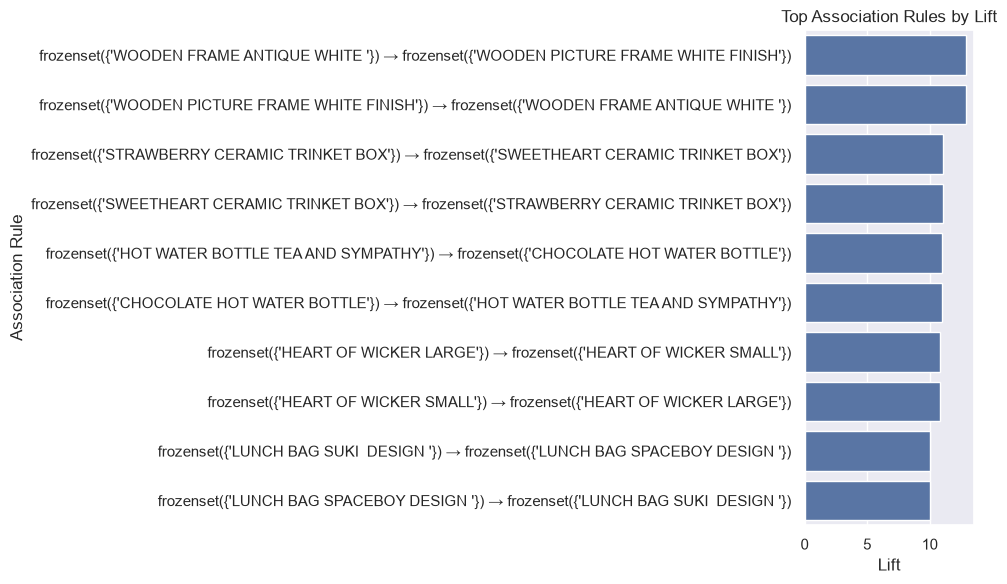

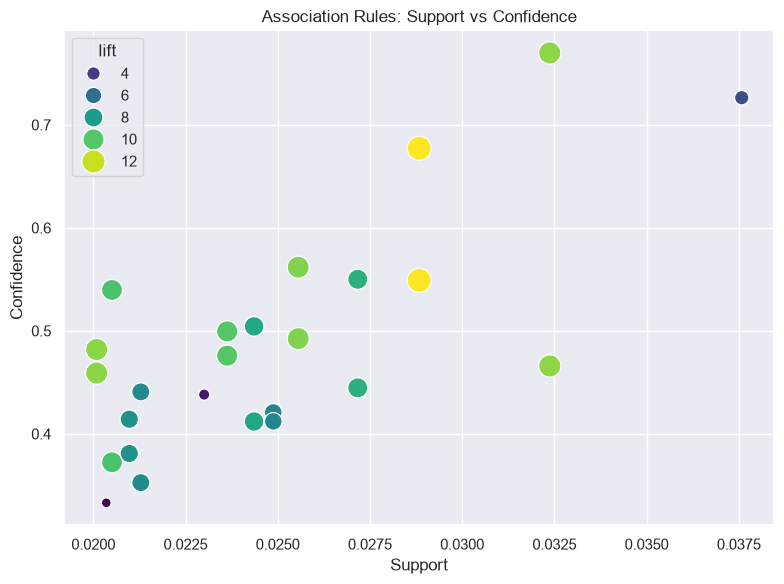


✅ ASSOCIATION RULE ANALYSIS COMPLETED


In [147]:
from mlxtend.frequent_patterns import association_rules

print("=" * 70)
print("🛒 ASSOCIATION RULE MINING")
print("=" * 70)
if "frequent_items" not in globals():
    print("❌ frequent_items is not defined.")
    print("Run your Apriori / frequent itemsets cell first.")
elif frequent_items.empty:
    print("❌ No frequent itemsets found.")
else:
    rules = association_rules(
        frequent_items,
        metric="confidence",
        min_threshold=0.3
    )
    if rules.empty:
        print("❌ No association rules found.")
    else:
        rules = rules.sort_values(
            by="lift",
            ascending=False
        )
        print(f"\n✅ Total Rules Generated: {len(rules)}")
        print("\n📋 Top Association Rules")
        print("-" * 70)
        display(
            rules[
                [
                    "antecedents",
                    "consequents",
                    "support",
                    "confidence",
                    "lift"
                ]
            ].head(10)
        )
        top_rules = rules.head(10).copy()
        top_rules["Rule"] = (
            top_rules["antecedents"].astype(str)
            + " → "
            + top_rules["consequents"].astype(str)
        )
        plt.figure(figsize=(10, 6))
        sns.barplot(
            data=top_rules,
            x="lift",
            y="Rule"
        )
        plt.title("Top Association Rules by Lift")
        plt.xlabel("Lift")
        plt.ylabel("Association Rule")
        plt.tight_layout()
        plt.show()
        plt.figure(figsize=(8, 6))
        sns.scatterplot(
            data=rules,
            x="support",
            y="confidence",
            size="lift",
            hue="lift",
            palette="viridis",
            sizes=(50, 300)
        )
        plt.title("Association Rules: Support vs Confidence")
        plt.xlabel("Support")
        plt.ylabel("Confidence")
        plt.tight_layout()
        plt.show()
print("\n" + "=" * 70)
print("✅ ASSOCIATION RULE ANALYSIS COMPLETED")
print("=" * 70)

📈 SALES PREDICTION

✅ Mean Absolute Error (MAE): 379.03
✅ Mean Squared Error (MSE): 981182.39
✅ Root Mean Squared Error (RMSE): 990.55
✅ R² Score: 0.08


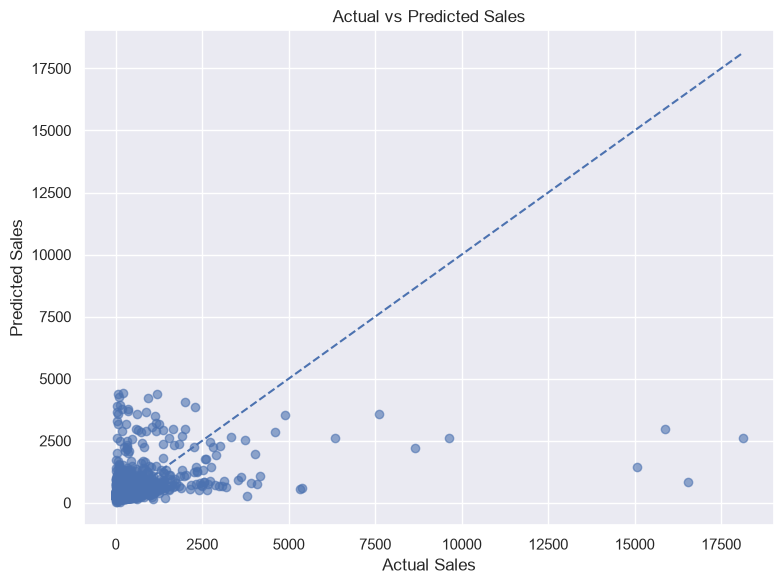


📋 Actual vs Predicted Values
----------------------------------------------------------------------


,Actual,Predicted
0,316.95,318.417972
1,125.70,355.878138
2,285.00,378.426452
3,207.71,335.149705
4,96.45,246.649657
5,96.45,201.443899
6,393.95,334.667392
7,167.85,324.278451
8,249.54,195.778869
9,175.50,529.352027



✅ PREDICTION ANALYSIS COMPLETED


In [148]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("📈 SALES PREDICTION")
print("=" * 70)
if "y_test" not in globals():
    print("❌ y_test is not defined.")
elif "predictions" not in globals():
    print("❌ predictions is not defined.")
else:
    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)
    print(f"\n✅ Mean Absolute Error (MAE): {mae:.2f}")
    print(f"✅ Mean Squared Error (MSE): {mse:.2f}")
    print(f"✅ Root Mean Squared Error (RMSE): {rmse:.2f}")
    print(f"✅ R² Score: {r2:.2f}")
    plt.figure(figsize=(8, 6))
    plt.scatter(
        y_test,
        predictions,
        alpha=0.6
    )
    min_value = min(
        np.min(y_test),
        np.min(predictions)
    )
    max_value = max(
        np.max(y_test),
        np.max(predictions)
    )
    plt.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--"
    )
    plt.title("Actual vs Predicted Sales")
    plt.xlabel("Actual Sales")
    plt.ylabel("Predicted Sales")
    plt.tight_layout()
    plt.show()
    comparison = pd.DataFrame({
        "Actual": np.array(y_test),
        "Predicted": np.array(predictions)
    })
    print("\n📋 Actual vs Predicted Values")
    print("-" * 70)
    display(comparison.head(10))
print("\n" + "=" * 70)
print("✅ PREDICTION ANALYSIS COMPLETED")
print("=" * 70)

📊 SHOPSMART OVERVIEW

👥 Total Customers: 4,312
💰 Total Sales: 8,798,233.74
🧾 Total Invoices: 19,213
📦 Total Products: 4,444

👤 Customer Category Distribution
----------------------------------------------------------------------
CustomerCategory
0    2156
1    2156
Name: count, dtype: int64


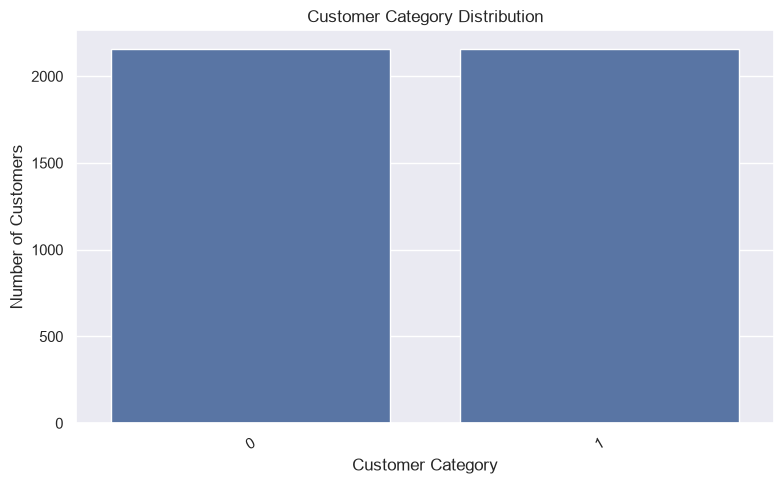


👥 Customer Cluster Distribution
----------------------------------------------------------------------


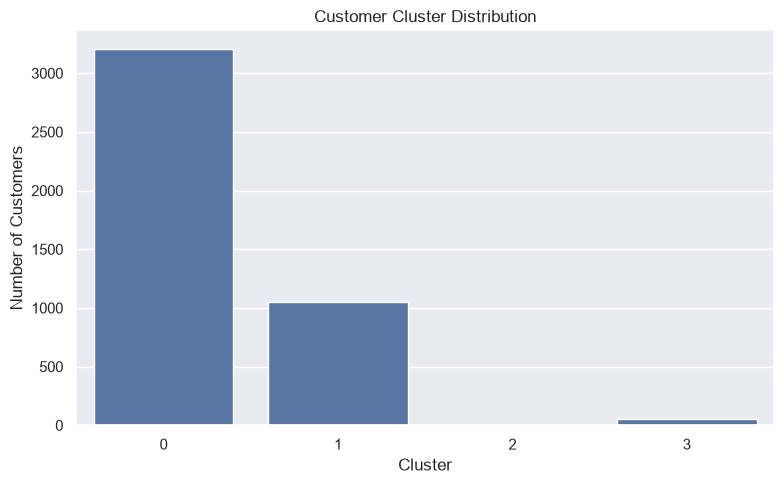


🤖 Model Performance
----------------------------------------------------------------------
Classification Accuracy: 82.97%
MAE: 379.03
RMSE: 990.55
R² Score: 0.08
Association Rules: 25

✅ OVERVIEW COMPLETED


In [149]:
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 70)
print("📊 SHOPSMART OVERVIEW")
print("=" * 70)
print(f"\n👥 Total Customers: {total_customers:,}")
print(f"💰 Total Sales: {total_sales:,.2f}")
print(f"🧾 Total Invoices: {total_invoices:,}")
print(f"📦 Total Products: {total_products:,}")
if "CustomerCategory" in rfm.columns:
    print("\n👤 Customer Category Distribution")
    print("-" * 70)
    print(rfm["CustomerCategory"].value_counts())

    plt.figure(figsize=(8, 5))
    sns.countplot(
        data=rfm,
        x="CustomerCategory"
    )
    plt.title("Customer Category Distribution")
    plt.xlabel("Customer Category")
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()
if "Cluster" in rfm.columns:
    print("\n👥 Customer Cluster Distribution")
    print("-" * 70)
    plt.figure(figsize=(8, 5))
    sns.countplot(
        data=rfm,
        x="Cluster"
    )
    plt.title("Customer Cluster Distribution")
    plt.xlabel("Cluster")
    plt.ylabel("Number of Customers")
    plt.tight_layout()
    plt.show()
print("\n🤖 Model Performance")
print("-" * 70)
if "accuracy" in globals():
    print(f"Classification Accuracy: {accuracy * 100:.2f}%")
if "mae" in globals():
    print(f"MAE: {mae:.2f}")
if "rmse" in globals():
    print(f"RMSE: {rmse:.2f}")
if "r2" in globals():
    print(f"R² Score: {r2:.2f}")
if "rules" in globals():
    print(f"Association Rules: {len(rules):,}")
print("\n" + "=" * 70)
print("✅ OVERVIEW COMPLETED")
print("=" * 70)

In [150]:
from IPython.display import display, HTML
import pandas as pd

overview_html = f"""
<h2>📊 Overview</h2>
<div style="display:flex;gap:15px;flex-wrap:wrap;">
<div style="padding:20px;border:1px solid #ddd;border-radius:10px;">
<b>👥 Customers</b><br><font size="5">{total_customers:,}</font>
</div>
<div style="padding:20px;border:1px solid #ddd;border-radius:10px;">
<b>💰 Sales</b><br><font size="5">{total_sales:,.2f}</font>
</div>
<div style="padding:20px;border:1px solid #ddd;border-radius:10px;">
<b>🧾 Invoices</b><br><font size="5">{total_invoices:,}</font>
</div>
<div style="padding:20px;border:1px solid #ddd;border-radius:10px;">
<b>📦 Products</b><br><font size="5">{total_products:,}</font>
</div>
</div>
"""
classification_html = f"""
<h2>🌳 Classification</h2>
<p><b>Decision Tree Accuracy:</b> {accuracy * 100:.2f}%</p>
{pd.DataFrame(classification_report(
    y_test_class,
    dt_pred,
    output_dict=True,
    zero_division=0
)).T.round(3).to_html()}
"""
cluster_html = ""
if "Cluster" in rfm.columns:
    cluster_html = f"""
    <h2>👥 Clustering</h2>
    <p><b>Number of Clusters:</b> {rfm["Cluster"].nunique()}</p>
    <p><b>Silhouette Score:</b> {sil_score:.3f}</p>
    {rfm.groupby("Cluster")[["Recency","Frequency","Monetary"]].mean().round(2).to_html()}
    """
else:
    cluster_html = "<h2>👥 Clustering</h2><p>Cluster data not available.</p>"
rules_count = len(rules) if "rules" in globals() else 0
association_html = f"""
<h2>🛒 Association Rules</h2>
<p><b>Total Rules:</b> {rules_count}</p>
"""
prediction_html = f"""
<h2>📈 Prediction</h2>
<p><b>MAE:</b> {mae:.2f}</p>
<p><b>MSE:</b> {mse:.2f}</p>
<p><b>RMSE:</b> {rmse:.2f}</p>
<p><b>R² Score:</b> {r2:.2f}</p>
"""
html = f"""
<style>
.tabs {{
    display:flex;
    gap:5px;
    margin-bottom:15px;
    flex-wrap:wrap;
}}
.tabbutton {{
    padding:12px 18px;
    border:none;
    background:#eeeeee;
    cursor:pointer;
    border-radius:6px;
    font-size:14px;
}}
.tabbutton:hover {{
    background:#dddddd;
}}
.tabcontent {{
    display:none;
    padding:20px;
    border:1px solid #ddd;
    border-radius:8px;
    background:white;
}}
table {{
    border-collapse:collapse;
    width:100%;
}}

th, td {{
    padding:8px;
    border:1px solid #ddd;
    text-align:center;
}}
th {{
    background:#f2f2f2;
}}
</style>
<div class="tabs">
<button class="tabbutton" onclick="openTab(event,'overview')">📊 Overview</button>
<button class="tabbutton" onclick="openTab(event,'classification')">🌳 Classification</button>
<button class="tabbutton" onclick="openTab(event,'clustering')">👥 Clustering</button>
<button class="tabbutton" onclick="openTab(event,'association')">🛒 Association Rules</button>
<button class="tabbutton" onclick="openTab(event,'prediction')">📈 Prediction</button>
</div>
<div id="overview" class="tabcontent">
{overview_html}
</div>
<div id="classification" class="tabcontent">
{classification_html}
</div>
<div id="clustering" class="tabcontent">
{cluster_html}
</div>
<div id="association" class="tabcontent">
{association_html}
</div>
<div id="prediction" class="tabcontent">
{prediction_html}
</div>
<script>
function openTab(evt, tabName) {{
    var i;
    var tabs = document.getElementsByClassName("tabcontent");
    for (i = 0; i < tabs.length; i++) {{
        tabs[i].style.display = "none";
    }}

    var buttons = document.getElementsByClassName("tabbutton");
    for (i = 0; i < buttons.length; i++) {{
        buttons[i].style.background = "#eeeeee";
    }}

    document.getElementById(tabName).style.display = "block";
    evt.currentTarget.style.background = "#cccccc";
}}
document.getElementById("overview").style.display = "block";
</script>
"""
display(HTML(html))